Import Pandas

In [1]:
import pandas as pd

Upload Your CSV File

In [2]:
from google.colab import files

uploaded = files.upload()

Saving customer_shopping_behavior.csv to customer_shopping_behavior.csv


Read the CSV File Using Pandas

In [3]:
df = pd.read_csv('customer_shopping_behavior.csv')

In [4]:
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [5]:
df.shape

(3900, 18)

In [6]:
df.columns

Index(['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category',
       'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season',
       'Review Rating', 'Subscription Status', 'Shipping Type',
       'Discount Applied', 'Promo Code Used', 'Previous Purchases',
       'Payment Method', 'Frequency of Purchases'],
      dtype='object')

In [7]:
df.dtypes

,0
Customer ID,int64
Age,int64
Gender,object
Item Purchased,object
Category,object
Purchase Amount (USD),int64
Location,object
Size,object
Color,object
Season,object


In [8]:
df.isnull().sum()

,0
Customer ID,0
Age,0
Gender,0
Item Purchased,0
Category,0
Purchase Amount (USD),0
Location,0
Size,0
Color,0
Season,0


In [9]:
df.isnull().sum().sum()

np.int64(37)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df[df.duplicated()]

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases


In [12]:
df.describe()

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3863.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.750065,25.351538
std,1125.977353,15.207589,23.685392,0.716983,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.800000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [13]:
df.select_dtypes(include='object').columns

Index(['Gender', 'Item Purchased', 'Category', 'Location', 'Size', 'Color',
       'Season', 'Subscription Status', 'Shipping Type', 'Discount Applied',
       'Promo Code Used', 'Payment Method', 'Frequency of Purchases'],
      dtype='object')

In [14]:
df['Gender'].value_counts()

,count
Gender,
Male,2652
Female,1248


In [15]:
df['Category'].value_counts()

,count
Category,
Clothing,1737
Accessories,1240
Footwear,599
Outerwear,324


In [16]:
df['Item Purchased'].value_counts()

,count
Item Purchased,
Blouse,171
Pants,171
Jewelry,171
Shirt,169
Dress,166
Sweater,164
Jacket,163
Coat,161
Sunglasses,161


In [17]:
df['Frequency of Purchases'].value_counts()

,count
Frequency of Purchases,
Every 3 Months,584
Annually,572
Quarterly,563
Monthly,553
Bi-Weekly,547
Fortnightly,542
Weekly,539


In [18]:
df['Subscription Status'].value_counts()

,count
Subscription Status,
No,2847
Yes,1053


In [19]:
df['Payment Method'].value_counts()

,count
Payment Method,
PayPal,677
Credit Card,671
Cash,670
Debit Card,636
Venmo,634
Bank Transfer,612


In [20]:
df['Review Rating'].value_counts().sort_index()

,count
Review Rating,
2.5,66
2.6,158
2.7,154
2.8,136
2.9,166
3.0,162
3.1,156
3.2,152
3.3,146


In [21]:
df.groupby('Gender')['Purchase Amount (USD)'].mean()

,Purchase Amount (USD)
Gender,
Female,60.249199
Male,59.536199


In [22]:
df.groupby('Category')['Purchase Amount (USD)'].mean().sort_values(ascending=False)

,Purchase Amount (USD)
Category,
Footwear,60.255426
Clothing,60.025331
Accessories,59.838710
Outerwear,57.172840


In [23]:
df.groupby('Subscription Status')['Purchase Amount (USD)'].mean()


,Purchase Amount (USD)
Subscription Status,
No,59.865121
Yes,59.491928


In [24]:
df.groupby(['Gender', 'Category'])['Purchase Amount (USD)'].mean()

Gender  Category   
Female  Accessories    60.762755
        Clothing       60.496403
        Footwear       59.472362
        Outerwear      58.425743
Male    Accessories    59.411557
        Clothing       59.803556
        Footwear       60.645000
        Outerwear      56.605381
Name: Purchase Amount (USD), dtype: float64

In [25]:
df.groupby('Category')['Purchase Amount (USD)'].sum().sort_values(ascending=False)

,Purchase Amount (USD)
Category,
Clothing,104264
Accessories,74200
Footwear,36093
Outerwear,18524


In [26]:
df.groupby('Season')['Purchase Amount (USD)'].sum().sort_values(ascending=False)


,Purchase Amount (USD)
Season,
Fall,60018
Spring,58679
Winter,58607
Summer,55777


In [27]:
df.groupby('Season')['Purchase Amount (USD)'].mean().sort_values(ascending=False)

,Purchase Amount (USD)
Season,
Fall,61.556923
Winter,60.357364
Spring,58.737738
Summer,58.405236


In [28]:
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 50, 70],
    labels=['18-25', '26-35', '36-50', '51-70']
)

In [29]:
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 50, 70],
    labels=['18-25', '26-35', '36-50', '51-70']
)

In [30]:
df['Age Group'].value_counts().sort_index()

,count
Age Group,
18-25,571
26-35,742
36-50,1111
51-70,1476


In [31]:
df.groupby('Age Group', observed=True)['Purchase Amount (USD)'].mean().round(2)

,Purchase Amount (USD)
Age Group,
18-25,60.65
26-35,59.76
36-50,59.07
51-70,59.95


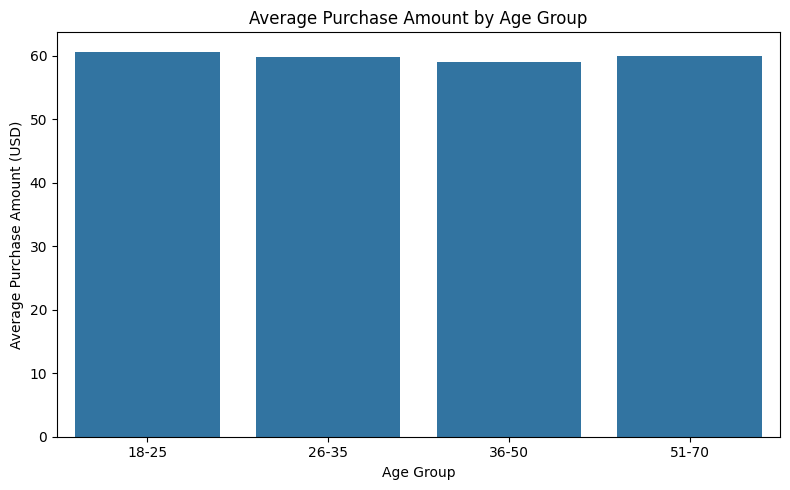

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

age_spending = df.groupby(
    'Age Group', observed=True
)['Purchase Amount (USD)'].mean()

plt.figure(figsize=(8, 5))
sns.barplot(x=age_spending.index, y=age_spending.values)

plt.title('Average Purchase Amount by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Purchase Amount (USD)')
plt.tight_layout()
plt.show()

In [33]:
df.groupby(['Gender', 'Category']).size().unstack()

Category,Accessories,Clothing,Footwear,Outerwear
Gender,,,,
Female,392,556,199,101
Male,848,1181,400,223


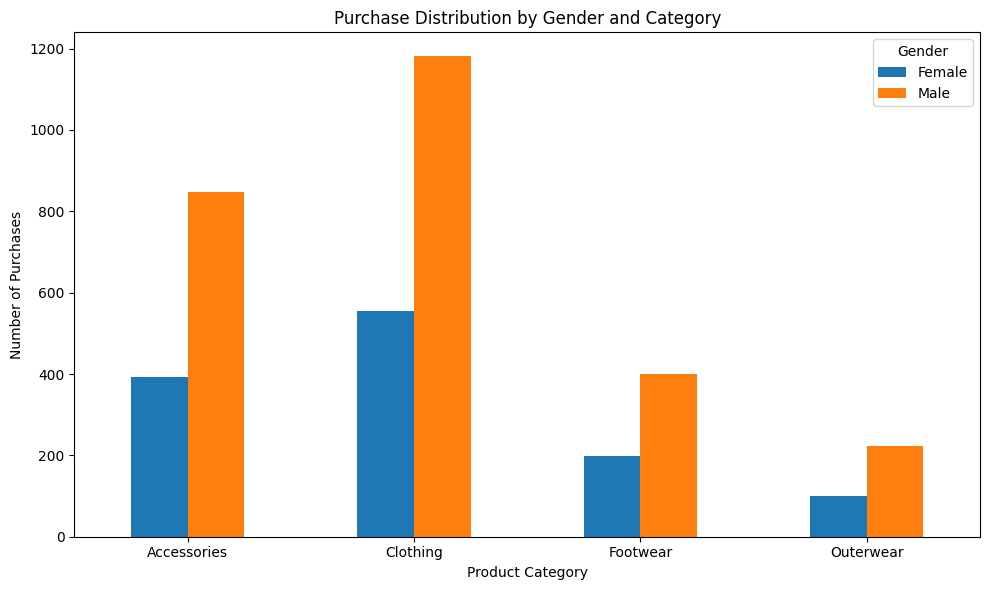

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

gender_category = pd.crosstab(
    df['Category'],
    df['Gender']
)

gender_category.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Purchase Distribution by Gender and Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Purchases')
plt.xticks(rotation=0)
plt.legend(title='Gender')
plt.tight_layout()
plt.show()

In [35]:
df.groupby('Payment Method')['Purchase Amount (USD)'].sum().sort_values(ascending=False)

,Purchase Amount (USD)
Payment Method,
Credit Card,40310
PayPal,40109
Cash,40002
Debit Card,38742
Venmo,37374
Bank Transfer,36544


In [36]:
df.groupby('Payment Method')['Purchase Amount (USD)'].mean().sort_values(ascending=False).round(2)

,Purchase Amount (USD)
Payment Method,
Debit Card,60.92
Credit Card,60.07
Bank Transfer,59.71
Cash,59.70
PayPal,59.25
Venmo,58.95


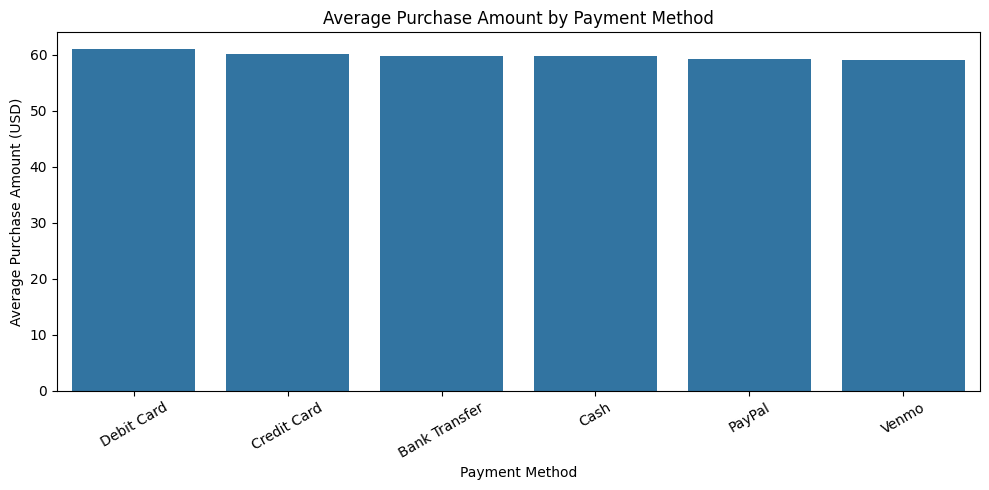

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

payment_spending = df.groupby(
    'Payment Method'
)['Purchase Amount (USD)'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=payment_spending.index, y=payment_spending.values)

plt.title('Average Purchase Amount by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Average Purchase Amount (USD)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [38]:
df['Discount Applied'].value_counts()

,count
Discount Applied,
No,2223
Yes,1677


In [39]:
df.groupby('Discount Applied')['Purchase Amount (USD)'].mean().round(2)

,Purchase Amount (USD)
Discount Applied,
No,60.13
Yes,59.28


In [40]:
df.groupby('Discount Applied')['Purchase Amount (USD)'].sum().sort_values(ascending=False)

,Purchase Amount (USD)
Discount Applied,
No,133670
Yes,99411


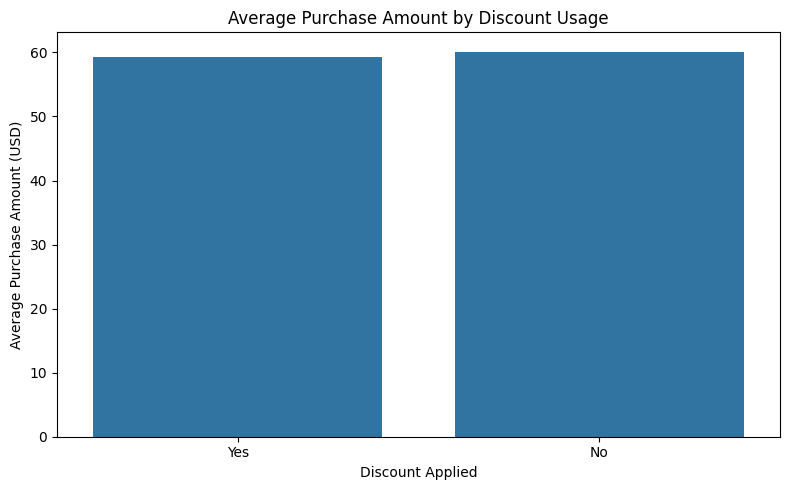

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Discount Applied',
    y='Purchase Amount (USD)',
    errorbar=None
)

plt.title('Average Purchase Amount by Discount Usage')
plt.xlabel('Discount Applied')
plt.ylabel('Average Purchase Amount (USD)')

plt.tight_layout()
plt.show()

In [42]:
df.groupby('Category')['Review Rating'].mean().sort_values(ascending=False).round(2)

,Review Rating
Category,
Footwear,3.79
Accessories,3.77
Outerwear,3.75
Clothing,3.72


In [43]:
df.groupby('Category')['Subscription Status'].value_counts()

Category     Subscription Status
Accessories  No                      906
             Yes                     334
Clothing     No                     1280
             Yes                     457
Footwear     No                      428
             Yes                     171
Outerwear    No                      233
             Yes                      91
Name: count, dtype: int64

In [44]:
subscription_table = pd.crosstab(
    df['Category'],
    df['Subscription Status']
)

subscription_table['Total Customers'] = subscription_table.sum(axis=1)

subscription_table['Subscription Rate (%)'] = (
    subscription_table['Yes'] /
    subscription_table['Total Customers'] * 100
).round(2)

subscription_table.sort_values(
    'Subscription Rate (%)',
    ascending=False
)

Subscription Status,No,Yes,Total Customers,Subscription Rate (%)
Category,,,,
Footwear,428,171,599,28.55
Outerwear,233,91,324,28.09
Accessories,906,334,1240,26.94
Clothing,1280,457,1737,26.31


In [45]:
pd.crosstab(
    df['Frequency of Purchases'],
    df['Subscription Status']
)

Subscription Status,No,Yes
Frequency of Purchases,,
Annually,412,160
Bi-Weekly,407,140
Every 3 Months,430,154
Fortnightly,389,153
Monthly,404,149
Quarterly,423,140
Weekly,382,157


In [46]:
frequency_table = pd.crosstab(
    df['Frequency of Purchases'],
    df['Subscription Status']
)

frequency_table['Total Customers'] = frequency_table.sum(axis=1)

frequency_table['Subscription Rate (%)'] = (
    frequency_table['Yes'] /
    frequency_table['Total Customers'] * 100
).round(2)

frequency_table.sort_values(
    'Subscription Rate (%)',
    ascending=False
)

Subscription Status,No,Yes,Total Customers,Subscription Rate (%)
Frequency of Purchases,,,,
Weekly,382,157,539,29.13
Fortnightly,389,153,542,28.23
Annually,412,160,572,27.97
Monthly,404,149,553,26.94
Every 3 Months,430,154,584,26.37
Bi-Weekly,407,140,547,25.59
Quarterly,423,140,563,24.87


In [47]:
age_analysis = df.groupby('Age Group').agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Revenue=('Purchase Amount (USD)', 'sum'),
    Average_Purchase=('Purchase Amount (USD)', 'mean')
).round(2)

age_analysis.sort_values('Total_Revenue', ascending=False)

/tmp/ipykernel_1993/3102081679.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_analysis = df.groupby('Age Group').agg(


,Total_Customers,Total_Revenue,Average_Purchase
Age Group,,,
51-70,1476,88480,59.95
36-50,1111,65629,59.07
26-35,742,44342,59.76
18-25,571,34630,60.65


In [48]:
df.groupby('Frequency of Purchases').agg(
    Total_Purchases=('Purchase Amount (USD)', 'count'),
    Average_Spending=('Purchase Amount (USD)', 'mean'),
    Total_Revenue=('Purchase Amount (USD)', 'sum')
).round(2).sort_values('Total_Revenue', ascending=False)

,Total_Purchases,Average_Spending,Total_Revenue
Frequency of Purchases,,,
Every 3 Months,584,60.08,35088
Annually,572,60.17,34419
Quarterly,563,59.98,33771
Bi-Weekly,547,60.69,33200
Monthly,553,59.33,32810
Fortnightly,542,59.05,32007
Weekly,539,58.97,31786


In [49]:
df.groupby(['Gender', 'Subscription Status']).agg(
    Customer_Count=('Customer ID', 'count'),
    Average_Spending=('Purchase Amount (USD)', 'mean'),
    Total_Revenue=('Purchase Amount (USD)', 'sum')
).round(2)

Customer_Count  Average_Spending  Total_Revenue
Gender Subscription Status                                                 
Female No                             1248             60.25          75191
Male   No                             1599             59.57          95245
       Yes                            1053             59.49          62645

In [50]:
df.groupby('Size').agg(
    Total_Transactions=('Customer ID', 'count'),
    Average_Purchase=('Purchase Amount (USD)', 'mean'),
    Average_Rating=('Review Rating', 'mean')
).round(2).sort_values(
    'Average_Purchase', ascending=False
)

,Total_Transactions,Average_Purchase,Average_Rating
Size,,,
S,663,61.04,3.80
XL,429,60.09,3.81
M,1755,59.92,3.72
L,1053,58.56,3.75


In [51]:
shipping_analysis = df.groupby('Shipping Type').agg(
    Total_Transactions=('Customer ID', 'count'),
    Total_Revenue=('Purchase Amount (USD)', 'sum'),
    Average_Purchase=('Purchase Amount (USD)', 'mean')
).round(2).sort_values(
    'Total_Revenue', ascending=False
)

shipping_analysis

,Total_Transactions,Total_Revenue,Average_Purchase
Shipping Type,,,
Free Shipping,675,40777,60.41
Express,646,39067,60.48
Store Pickup,650,38931,59.89
Standard,654,38233,58.46
2-Day Shipping,627,38080,60.73
Next Day Air,648,37993,58.63


In [52]:
discount_category = df.groupby(
    ['Category', 'Discount Applied']
).agg(
    Transactions=('Customer ID', 'count'),
    Average_Purchase=('Purchase Amount (USD)', 'mean'),
    Total_Revenue=('Purchase Amount (USD)', 'sum')
).round(2)

discount_category

Transactions  Average_Purchase  Total_Revenue
Category    Discount Applied                                               
Accessories No                         697             60.89          42440
            Yes                        543             58.49          31760
Clothing    No                        1006             60.22          60585
            Yes                        731             59.75          43679
Footwear    No                         340             59.08          20087
            Yes                        259             61.80          16006
Outerwear   No                         180             58.66          10558
            Yes                        144             55.32           7966